# Notebook 02: Huis Data Exploratie 

In [1]:
import pandas as pd
from pathlib import Path
import matplotlib.pyplot as plt

DATA_DIR = Path.cwd().parent / "locatie_data"

In [2]:
df_huis = pd.read_parquet(
    DATA_DIR / "huis788.parquet"
)

### Algemene controle

In [3]:
print("Shape:", df_huis.shape)
print("Chronologisch:", df_huis["timestamp"].is_monotonic_increasing)

df_huis.info()

Shape: (3057890, 25)
Chronologisch: True
<class 'pandas.DataFrame'>
RangeIndex: 3057890 entries, 0 to 3057889
Data columns (total 25 columns):
 #   Column         Dtype                           
---  ------         -----                           
 0   timestamp      datetime64[us, Europe/Amsterdam]
 1   CO2            float64                         
 2   CTYPE          str                             
 3   ENAME          str                             
 4   ENE            float64                         
 5   ETYPE          str                             
 6   POW            float64                         
 7   source_zip     str                             
 8   source_csv     str                             
 9   source_folder  str                             
 10  CO2_IMP        float64                         
 11  COST_IMP       float64                         
 12  CTYPEC         str                             
 13  ENE_CNT_IMP    float64                         
 14  ENE_

In [4]:
df_huis.head()

,timestamp,CO2,CTYPE,ENAME,ENE,ETYPE,POW,source_zip,source_csv,source_folder,...,CO2_EXP,COST,COST_EXP,ENE_CNT_EXP,ENE_EXP,CO2EQ,ESTYPE,forecast.ENE,forecast.POW,PRICE
0,2024-03-08 01:00:00+01:00,NaN,electricity,boiler-16eda211b788,NaN,boiler,6.504839,240308_boiler-16eda211b788_7813337caa64460dd37...,240308_boiler-16eda211b788_7813337caa64460dd37...,boiler-16eda211b788,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,2024-03-08 01:00:00+01:00,NaN,electricity,hoofdmeter-16eda211b788,NaN,powermeter,97.580645,240308_hoofdmeter-16eda211b788_583371188e6bd6b...,240308_hoofdmeter-16eda211b788_583371188e6bd6b...,hoofdmeter-16eda211b788,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,2024-03-08 01:00:00+01:00,NaN,electricity,overig-16eda211b788,NaN,powermeter,34.007143,240308_overig-16eda211b788_c9a2174e7ac825737c3...,240308_overig-16eda211b788_c9a2174e7ac825737c3...,overig-16eda211b788,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,2024-03-08 01:00:00+01:00,NaN,electricity,totaalverbruik-16eda211b788,NaN,powermeter,100.000000,240308_totaalverbruik-16eda211b788_15b395d52b6...,240308_totaalverbruik-16eda211b788_15b395d52b6...,totaalverbruik-16eda211b788,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,2024-03-08 01:00:00+01:00,NaN,electricity,wcdskeukeneilandenvaatwasser-16eda211b788,NaN,dishwasher,42.476190,240308_wcdskeukeneilandenvaatwasser-16eda211b7...,240308_wcdskeukeneilandenvaatwasser-16eda211b7...,wcdskeukeneilandenvaatwasser-16eda211b788,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


### Overzicht van de meetreeksen

In [5]:
# maakt per ENAME een samenvatting vd timestamps 
overzicht = (df_huis.groupby("ENAME").agg(
        aantal_rijen=("timestamp", "size"), # telt hoeveel rijen er per ENAME zijn 
        unieke_timestamps=("timestamp", "nunique"), # telt hoeveel verschillende timestamps er per ENAME zijn 
        eerste_meting=("timestamp", "min"), # eerste timestamp die voorkomt per ENAME 
        laatste_meting=("timestamp", "max") # laatste timestamp die voorkomt per ENAME
    )
)

# berekent hoeveel extra rijen er zijn doordat timestamps vaker dan 1 keer voorkomen 
overzicht["dubbele_timestamps"] = (overzicht["aantal_rijen"] - overzicht["unieke_timestamps"])

overzicht.sort_values("aantal_rijen", ascending=False)

,aantal_rijen,unieke_timestamps,eerste_meting,laatste_meting,dubbele_timestamps
ENAME,,,,,
overig-16eda211b788,398790,230149,2024-03-08 01:00:00+01:00,2026-09-10 01:55:00+02:00,168641
totaalverbruik-16eda211b788,397154,228499,2024-03-08 01:00:00+01:00,2026-09-10 01:55:00+02:00,168655
wasmachine-16eda211b788,381248,214270,2024-03-08 01:05:00+01:00,2026-09-10 01:55:00+02:00,166978
omvormer-16eda211b788,368720,200703,2024-03-08 06:55:00+01:00,2026-09-10 01:55:00+02:00,168017
boiler-16eda211b788,362465,195413,2024-03-08 01:00:00+01:00,2026-09-10 01:55:00+02:00,167052
wcdskeukeneilandenvaatwasser-16eda211b788,361006,194555,2024-03-08 01:00:00+01:00,2026-09-10 01:55:00+02:00,166451
hoofdmeter-16eda211b788,318076,188249,2024-03-08 01:00:00+01:00,2026-09-07 08:05:00+02:00,129827
priceele_c911efafaa,171217,171217,2025-01-14 09:20:00+01:00,2026-09-10 01:55:00+02:00,0
co2ele_combined,168068,168059,2024-03-08 01:05:00+01:00,2026-09-10 01:55:00+02:00,9


### Totaalverbruik bekijken

In [6]:
TOTAALVERBRUIK = "totaalverbruik-16eda211b788"

# aparte dataframe met alleen de rijen van totaalverbruik
df_totaal = (df_huis[df_huis["ENAME"] == TOTAALVERBRUIK].copy()
             .sort_values("timestamp").reset_index(drop=True)
)

print("Aantal rijen:", len(df_totaal))
print("Unieke timestamps:", df_totaal["timestamp"].nunique())

# berekent hoeveel extra rijen er zijn doordat timestamps vaker voorkomen
print("Dubbele timestamps:",
    len(df_totaal) - df_totaal["timestamp"].nunique()
)

df_totaal.head()

Aantal rijen: 397154
Unieke timestamps: 228499
Dubbele timestamps: 168655


,timestamp,CO2,CTYPE,ENAME,ENE,ETYPE,POW,source_zip,source_csv,source_folder,...,CO2_EXP,COST,COST_EXP,ENE_CNT_EXP,ENE_EXP,CO2EQ,ESTYPE,forecast.ENE,forecast.POW,PRICE
0,2024-03-08 01:00:00+01:00,NaN,electricity,totaalverbruik-16eda211b788,NaN,powermeter,100.0,240308_totaalverbruik-16eda211b788_15b395d52b6...,240308_totaalverbruik-16eda211b788_15b395d52b6...,totaalverbruik-16eda211b788,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,2024-03-08 01:05:00+01:00,1.533333,electricity,totaalverbruik-16eda211b788,8.333333,powermeter,40.0,240308_totaalverbruik-16eda211b788_15b395d52b6...,240308_totaalverbruik-16eda211b788_15b395d52b6...,totaalverbruik-16eda211b788,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,2024-03-08 01:10:00+01:00,0.613333,electricity,totaalverbruik-16eda211b788,3.333333,powermeter,45.0,240308_totaalverbruik-16eda211b788_15b395d52b6...,240308_totaalverbruik-16eda211b788_15b395d52b6...,totaalverbruik-16eda211b788,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,2024-03-08 01:15:00+01:00,0.690000,electricity,totaalverbruik-16eda211b788,3.750000,powermeter,NaN,240308_totaalverbruik-16eda211b788_15b395d52b6...,240308_totaalverbruik-16eda211b788_15b395d52b6...,totaalverbruik-16eda211b788,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,2024-03-08 01:20:00+01:00,NaN,electricity,totaalverbruik-16eda211b788,NaN,powermeter,45.0,240308_totaalverbruik-16eda211b788_15b395d52b6...,240308_totaalverbruik-16eda211b788_15b395d52b6...,totaalverbruik-16eda211b788,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [7]:
timestamps = df_totaal["timestamp"]
df_totaal[timestamps.isin(timestamps[timestamps.duplicated()])].sort_values("timestamp")

,timestamp,CO2,CTYPE,ENAME,ENE,ETYPE,POW,source_zip,source_csv,source_folder,...,CO2_EXP,COST,COST_EXP,ENE_CNT_EXP,ENE_EXP,CO2EQ,ESTYPE,forecast.ENE,forecast.POW,PRICE
36129,2024-10-05 20:10:00+02:00,7.140,electricity,totaalverbruik-16eda211b788,NaN,powermeter,103.5,241005_totaalverbruik-16eda211b788_c608774f559...,241005_totaalverbruik-16eda211b788_c608774f559...,totaalverbruik-16eda211b788,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
36130,2024-10-05 20:10:00+02:00,NaN,electricity,totaalverbruik-16eda211b788,15.0,powermeter,180.0,241005_totaalverbruik-16eda211b788_c608774f559...,241005_totaalverbruik-16eda211b788_c608774f559...,totaalverbruik-16eda211b788,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
59767,2025-01-23 00:05:00+01:00,NaN,electricity,totaalverbruik-16eda211b788,NaN,powermeter,NaN,250122_totaalverbruik-16eda211b788_661c17963b3...,250122_totaalverbruik-16eda211b788_661c17963b3...,totaalverbruik-16eda211b788,...,NaN,0.003303,0.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN
59768,2025-01-23 00:05:00+01:00,6.357,electricity,totaalverbruik-16eda211b788,13.0,powermeter,160.0,250122_totaalverbruik-16eda211b788_661c17963b3...,250122_totaalverbruik-16eda211b788_661c17963b3...,totaalverbruik-16eda211b788,...,0.0,NaN,NaN,0.0,0.0,NaN,NaN,NaN,NaN,NaN
59769,2025-01-23 00:10:00+01:00,NaN,electricity,totaalverbruik-16eda211b788,NaN,powermeter,NaN,250122_totaalverbruik-16eda211b788_661c17963b3...,250122_totaalverbruik-16eda211b788_661c17963b3...,totaalverbruik-16eda211b788,...,NaN,0.002541,0.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
397149,2026-09-10 01:45:00+02:00,NaN,electricity,totaalverbruik-16eda211b788,NaN,powermeter,NaN,260909_totaalverbruik-16eda211b788_3f0b9a87181...,260909_totaalverbruik-16eda211b788_3f0b9a87181...,totaalverbruik-16eda211b788,...,NaN,0.000000,0.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN
397150,2026-09-10 01:50:00+02:00,0.000,electricity,totaalverbruik-16eda211b788,0.0,powermeter,NaN,260909_totaalverbruik-16eda211b788_3f0b9a87181...,260909_totaalverbruik-16eda211b788_3f0b9a87181...,totaalverbruik-16eda211b788,...,0.0,NaN,NaN,0.0,0.0,NaN,NaN,NaN,NaN,NaN
397151,2026-09-10 01:50:00+02:00,NaN,electricity,totaalverbruik-16eda211b788,NaN,powermeter,NaN,260909_totaalverbruik-16eda211b788_3f0b9a87181...,260909_totaalverbruik-16eda211b788_3f0b9a87181...,totaalverbruik-16eda211b788,...,NaN,0.000000,0.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN
397152,2026-09-10 01:55:00+02:00,0.000,electricity,totaalverbruik-16eda211b788,0.0,powermeter,610.0,260909_totaalverbruik-16eda211b788_3f0b9a87181...,260909_totaalverbruik-16eda211b788_3f0b9a87181...,totaalverbruik-16eda211b788,...,0.0,NaN,NaN,0.0,0.0,NaN,NaN,NaN,NaN,NaN


In [8]:
df_totaal["timestamp"].value_counts().value_counts().sort_index()

count
1     59844
2    168655
Name: count, dtype: int64

In [9]:
print(df_huis.columns.tolist())

['timestamp', 'CO2', 'CTYPE', 'ENAME', 'ENE', 'ETYPE', 'POW', 'source_zip', 'source_csv', 'source_folder', 'CO2_IMP', 'COST_IMP', 'CTYPEC', 'ENE_CNT_IMP', 'ENE_IMP', 'CO2_EXP', 'COST', 'COST_EXP', 'ENE_CNT_EXP', 'ENE_EXP', 'CO2EQ', 'ESTYPE', 'forecast.ENE', 'forecast.POW', 'PRICE']


In [10]:
print(df_totaal.columns.tolist())
df_totaal.head()

['timestamp', 'CO2', 'CTYPE', 'ENAME', 'ENE', 'ETYPE', 'POW', 'source_zip', 'source_csv', 'source_folder', 'CO2_IMP', 'COST_IMP', 'CTYPEC', 'ENE_CNT_IMP', 'ENE_IMP', 'CO2_EXP', 'COST', 'COST_EXP', 'ENE_CNT_EXP', 'ENE_EXP', 'CO2EQ', 'ESTYPE', 'forecast.ENE', 'forecast.POW', 'PRICE']


,timestamp,CO2,CTYPE,ENAME,ENE,ETYPE,POW,source_zip,source_csv,source_folder,...,CO2_EXP,COST,COST_EXP,ENE_CNT_EXP,ENE_EXP,CO2EQ,ESTYPE,forecast.ENE,forecast.POW,PRICE
0,2024-03-08 01:00:00+01:00,NaN,electricity,totaalverbruik-16eda211b788,NaN,powermeter,100.0,240308_totaalverbruik-16eda211b788_15b395d52b6...,240308_totaalverbruik-16eda211b788_15b395d52b6...,totaalverbruik-16eda211b788,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,2024-03-08 01:05:00+01:00,1.533333,electricity,totaalverbruik-16eda211b788,8.333333,powermeter,40.0,240308_totaalverbruik-16eda211b788_15b395d52b6...,240308_totaalverbruik-16eda211b788_15b395d52b6...,totaalverbruik-16eda211b788,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,2024-03-08 01:10:00+01:00,0.613333,electricity,totaalverbruik-16eda211b788,3.333333,powermeter,45.0,240308_totaalverbruik-16eda211b788_15b395d52b6...,240308_totaalverbruik-16eda211b788_15b395d52b6...,totaalverbruik-16eda211b788,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,2024-03-08 01:15:00+01:00,0.690000,electricity,totaalverbruik-16eda211b788,3.750000,powermeter,NaN,240308_totaalverbruik-16eda211b788_15b395d52b6...,240308_totaalverbruik-16eda211b788_15b395d52b6...,totaalverbruik-16eda211b788,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,2024-03-08 01:20:00+01:00,NaN,electricity,totaalverbruik-16eda211b788,NaN,powermeter,45.0,240308_totaalverbruik-16eda211b788_15b395d52b6...,240308_totaalverbruik-16eda211b788_15b395d52b6...,totaalverbruik-16eda211b788,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


### POW bekijken 

In [11]:
df_totaal[["timestamp", "POW"]].head()

,timestamp,POW
0,2024-03-08 01:00:00+01:00,100.0
1,2024-03-08 01:05:00+01:00,40.0
2,2024-03-08 01:10:00+01:00,45.0
3,2024-03-08 01:15:00+01:00,NaN
4,2024-03-08 01:20:00+01:00,45.0


In [12]:
df_totaal[["timestamp", "POW"]].isnull().sum()

timestamp         0
POW          190850
dtype: int64

In [13]:
df_totaal['POW'].describe().T

count    206304.000000
mean        697.976404
std         770.692129
min       -2207.500000
25%         104.000000
50%         406.577731
75%        1059.746822
max        7255.975806
Name: POW, dtype: float64

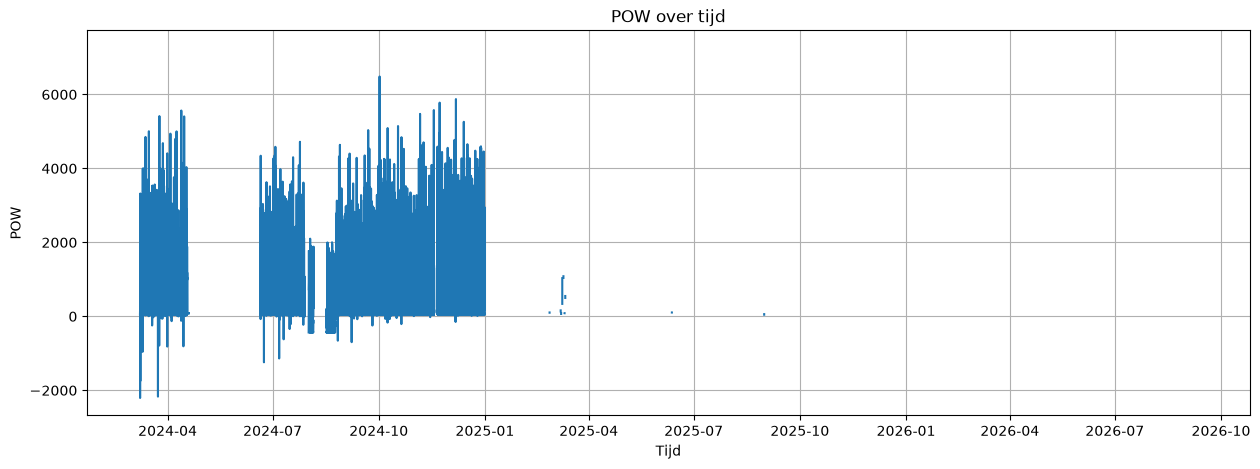

In [14]:
# Timestamp omzetten naar datetime
df_totaal["timestamp"] = pd.to_datetime(df_totaal["timestamp"])

# Sorteren op tijd
df_totaal = df_totaal.sort_values("timestamp")

# POW plotten tegenover tijd
plt.figure(figsize=(15, 5))
plt.plot(df_totaal["timestamp"], df_totaal["POW"])

plt.xlabel("Tijd")
plt.ylabel("POW")
plt.title("POW over tijd")
plt.grid()
plt.show()

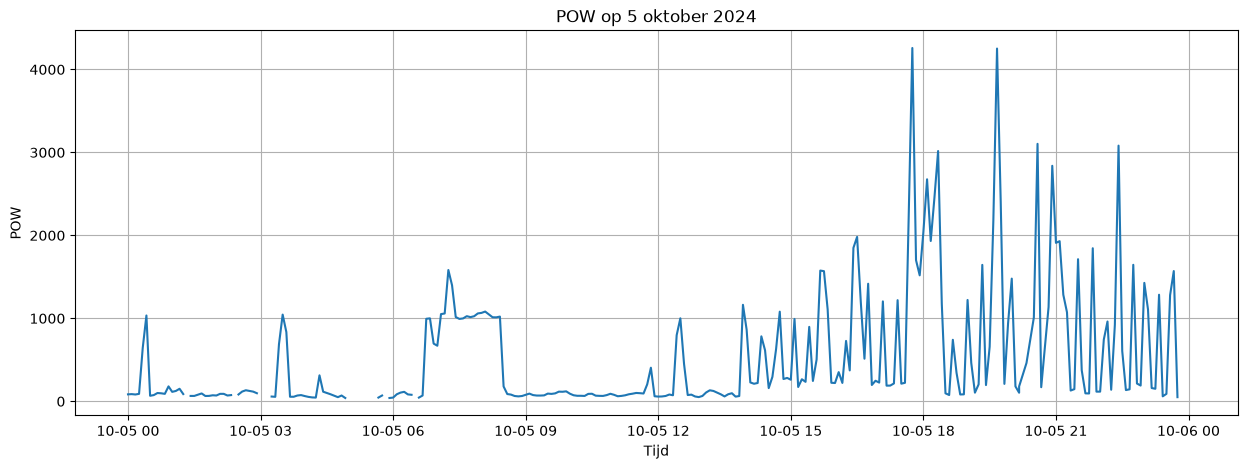

In [15]:
dag = df_totaal[
    (df_totaal["timestamp"] >= "2024-10-05") &
    (df_totaal["timestamp"] < "2024-10-06")
]

plt.figure(figsize=(15, 5))
plt.plot(dag["timestamp"], dag["POW"])

plt.xlabel("Tijd")
plt.ylabel("POW")
plt.title("POW op 5 oktober 2024")
plt.grid()
plt.show()

In [16]:
print("Eerste timestamp:", df_totaal["timestamp"].min())
print("Laatste timestamp:", df_totaal["timestamp"].max())

print(
    "Laatste timestamp met geldige POW:",
    df_totaal.loc[df_totaal["POW"].notna(), "timestamp"].max()
)

Eerste timestamp: 2024-03-08 01:00:00+01:00
Laatste timestamp: 2026-09-10 01:55:00+02:00
Laatste timestamp met geldige POW: 2026-09-10 01:55:00+02:00


### Punt 3 check?

In [17]:
#Alleen rijen waar POW aanwezig is
df_pow = df_huis[df_huis["POW"].notna()].copy()

#Zoektype van Pieter
filter = ["timestamp", "CTYPE", "CTYPEC", "ENAME", "ETYPE"]

dubbel = df_pow.duplicated(subset=filter,keep=False)

dubbele_pow = (df_pow.loc[dubbel].sort_values(filter))

dubbele_pow

,timestamp,CO2,CTYPE,ENAME,ENE,ETYPE,POW,source_zip,source_csv,source_folder,...,CO2_EXP,COST,COST_EXP,ENE_CNT_EXP,ENE_EXP,CO2EQ,ESTYPE,forecast.ENE,forecast.POW,PRICE
224530,2024-10-05 20:10:00+02:00,7.140000,electricity,totaalverbruik-16eda211b788,NaN,powermeter,103.500000,241005_totaalverbruik-16eda211b788_c608774f559...,241005_totaalverbruik-16eda211b788_c608774f559...,totaalverbruik-16eda211b788,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
224531,2024-10-05 20:10:00+02:00,NaN,electricity,totaalverbruik-16eda211b788,15.000000,powermeter,180.000000,241005_totaalverbruik-16eda211b788_c608774f559...,241005_totaalverbruik-16eda211b788_c608774f559...,totaalverbruik-16eda211b788,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
224525,2024-10-05 20:10:00+02:00,5.910333,electricity,hoofdmeter-16eda211b788,NaN,powermeter,112.941176,241005_hoofdmeter-16eda211b788_8f02b76d3db5193...,241005_hoofdmeter-16eda211b788_8f02b76d3db5193...,hoofdmeter-16eda211b788,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
224526,2024-10-05 20:10:00+02:00,NaN,electricity,hoofdmeter-16eda211b788,12.416667,powermeter,181.666667,241005_hoofdmeter-16eda211b788_8f02b76d3db5193...,241005_hoofdmeter-16eda211b788_8f02b76d3db5193...,hoofdmeter-16eda211b788,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
224521,2024-10-05 20:10:00+02:00,0.180849,electricity,boiler-16eda211b788,NaN,boiler,46.356818,241005_boiler-16eda211b788_e14afb7f21159dfdee2...,241005_boiler-16eda211b788_e14afb7f21159dfdee2...,boiler-16eda211b788,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
224522,2024-10-05 20:10:00+02:00,NaN,electricity,boiler-16eda211b788,0.379934,boiler,4.550000,241005_boiler-16eda211b788_e14afb7f21159dfdee2...,241005_boiler-16eda211b788_e14afb7f21159dfdee2...,boiler-16eda211b788,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
224528,2024-10-05 20:10:00+02:00,2.479769,electricity,overig-16eda211b788,NaN,powermeter,59.041071,241005_overig-16eda211b788_2058e3ce58a10957a48...,241005_overig-16eda211b788_2058e3ce58a10957a48...,overig-16eda211b788,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
224529,2024-10-05 20:10:00+02:00,NaN,electricity,overig-16eda211b788,5.209599,powermeter,63.043478,241005_overig-16eda211b788_2058e3ce58a10957a48...,241005_overig-16eda211b788_2058e3ce58a10957a48...,overig-16eda211b788,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
224532,2024-10-05 20:10:00+02:00,1.167115,electricity,wasmachine-16eda211b788,NaN,washingmachine,41.000000,241005_wasmachine-16eda211b788_57f80165066537e...,241005_wasmachine-16eda211b788_57f80165066537e...,wasmachine-16eda211b788,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
224533,2024-10-05 20:10:00+02:00,NaN,electricity,wasmachine-16eda211b788,2.451923,washingmachine,27.500000,241005_wasmachine-16eda211b788_57f80165066537e...,241005_wasmachine-16eda211b788_57f80165066537e...,wasmachine-16eda211b788,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [18]:
kolommen = [
    "timestamp",
    "CTYPE",
    "CTYPEC",
    "ENAME",
    "ETYPE",
    "POW"
]

dubbele_pow[kolommen].head(50)

,timestamp,CTYPE,CTYPEC,ENAME,ETYPE,POW
224530,2024-10-05 20:10:00+02:00,electricity,consumption,totaalverbruik-16eda211b788,powermeter,103.500000
224531,2024-10-05 20:10:00+02:00,electricity,consumption,totaalverbruik-16eda211b788,powermeter,180.000000
224525,2024-10-05 20:10:00+02:00,electricity,supply,hoofdmeter-16eda211b788,powermeter,112.941176
224526,2024-10-05 20:10:00+02:00,electricity,supply,hoofdmeter-16eda211b788,powermeter,181.666667
224521,2024-10-05 20:10:00+02:00,electricity,NaN,boiler-16eda211b788,boiler,46.356818
224522,2024-10-05 20:10:00+02:00,electricity,NaN,boiler-16eda211b788,boiler,4.550000
224528,2024-10-05 20:10:00+02:00,electricity,NaN,overig-16eda211b788,powermeter,59.041071
224529,2024-10-05 20:10:00+02:00,electricity,NaN,overig-16eda211b788,powermeter,63.043478
224532,2024-10-05 20:10:00+02:00,electricity,NaN,wasmachine-16eda211b788,washingmachine,41.000000
224533,2024-10-05 20:10:00+02:00,electricity,NaN,wasmachine-16eda211b788,washingmachine,27.500000
